# Part VI — The reset: past results or this weekend's pace?
**Proposal question:** *can a pre-race model predict which drivers score points (top 10) through a regulation reset, and should it rely on past results or on the current weekend's pace?*

- **H1** after a reset, weekend pace (practice, qualifying, grid) predicts better than past results
- **H2** past results regain their value as the new season progresses
- **H3** live forecasts for the remaining 2026 races are as accurate as the simulation (tested after the races)

The same logistic regression is trained with different sets of variables. Each 2014 and 2026 race is predicted by a model re-trained on everything before it (car profile and k-means included). **New variables for the reset (the 2026 power units are about 50% electric):** `pu_works` (works or lead-partner team of the engine maker) and `pu_change` (the team changed engine supplier this season).
Code: `f1duel/reset.py`.

Points that changed hands over the winter: 2014 42%, 2026 34% (median of other years 21%)
Mechanical retirements: 2025 3% -> 2026 13%; 2013 6% -> 2014 13%


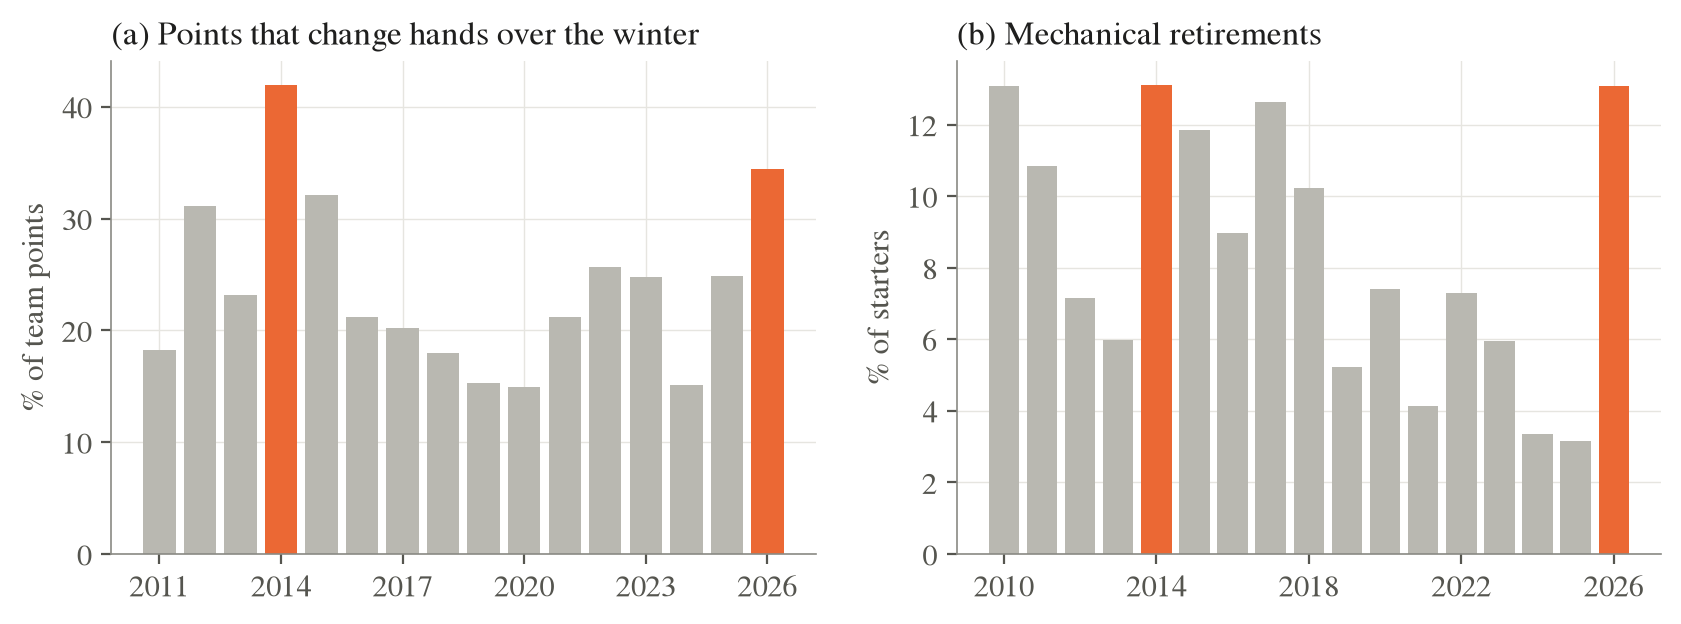

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
from f1duel.reset import MODELS
R = json.load(open('../results/reset_summary.json'))
F = R['facts']
print(f"Points that changed hands over the winter: 2014 {F['points_changing_hands']['2014']:.0%}, 2026 {F['points_changing_hands']['2026']:.0%} (median of other years {np.median([v for y, v in F['points_changing_hands'].items() if y not in ('2014', '2026')]):.0%})")
print(f"Mechanical retirements: 2025 {F['mechanical_dnf_rate']['2025']:.0%} -> 2026 {F['mechanical_dnf_rate']['2026']:.0%}; 2013 {F['mechanical_dnf_rate']['2013']:.0%} -> 2014 {F['mechanical_dnf_rate']['2014']:.0%}")
from IPython.display import Image; display(Image('../figures/06_reset_facts.png', width=800))

In [2]:
rows = []
for test in ['Reset 2026', 'Reset 2014', 'Normal seasons 2020-2025']:
    for n, v in R[test]['models'].items():
        rows.append({'Test': test, 'Model': n, 'Cross-entropy rounds 1-5': v['logloss_early'], 'Cross-entropy rounds 6+': v['logloss_late'],
                     'Cross-entropy all': v['logloss'], 'AUC': v['auc'], 'Precision = recall (of 10)': v['named'] / 10, 'Gain vs grid': v['gain_vs_grid'][0]})
T = pd.DataFrame(rows).set_index(['Test', 'Model']).round(4); T

Cross-entropy rounds 1-5  Cross-entropy rounds 6+  Cross-entropy all     AUC  \
Test                     Model                                                                                                      
Reset 2026               Past results only                             0.5686                   0.5068             0.5241  0.8236   
                         Past results + power unit                     0.5733                   0.5085             0.5266  0.8233   
                         Grid position only                            0.5057                   0.5032             0.5039  0.8302   
                         Weekend pace only                             0.5259                   0.4708             0.4862  0.8471   
                         Full model (no power unit)                    0.5211                   0.4632             0.4795  0.8540   
                         Full model                                    0.5226                   0.4623             0.4792  0.8536   
Reset 2014               Past results only                             0.5147                   0.4739             0.4849  0.8464   
                         Past results + power unit                     0.5002                   0.4782             0.4841  0.8500   
                         Grid position only                            0.4715                   0.4954             0.4889  0.8445   
                         Weekend pace only                             0.4575                   0.4761             0.4711  0.8576   
                         Full model (no power unit)                    0.4394                   0.4381             0.4385  0.8777   
                         Full model                                    0.4350                   0.4432             0.4410  0.8745   
Normal seasons 2020-2025 Past results only                             0.5308                   0.5359             0.5347  0.8135   
                         Past results + power unit                     0.5321                   0.5333             0.5330  0.8143   
                         Grid position only                            0.5027                   0.5095             0.5079  0.8300   
                         Weekend pace only                             0.5046                   0.5079             0.5071  0.8374   
                         Full model (no power unit)                    0.4830                   0.4816             0.4819  0.8545   
                         Full model                                    0.4841                   0.4806             0.4814  0.8550   

                                                     Precision = recall (of 10)  Gain vs grid  
Test                     Model                                                                 
Reset 2026               Past results only                               0.7471       -0.0588  
                         Past results + power unit                       0.7471       -0.0588  
                         Grid position only                              0.7529        0.0000  
                         Weekend pace only                               0.7647        0.1176  
                         Full model (no power unit)                      0.7647        0.1176  
                         Full model                                      0.7588        0.0588  
Reset 2014               Past results only                               0.7579        0.0000  
                         Past results + power unit                       0.7684        0.1053  
                         Grid position only                              0.7579        0.0000  
                         Weekend pace only                               0.7526       -0.0526  
                         Full model (no power unit)                      0.7737        0.1579  
                         Full model                                      0.7579        0.0000  
Normal seasons 2020-2025 Past results only      

Reset 2026: H1 weekend beats past early by +0.0428 cross-entropy; H2 gap later +0.0360 (positive = weekend better); power unit changes the full model by -0.0003
Reset 2014: H1 weekend beats past early by +0.0572 cross-entropy; H2 gap later -0.0021 (positive = weekend better); power unit changes the full model by +0.0025


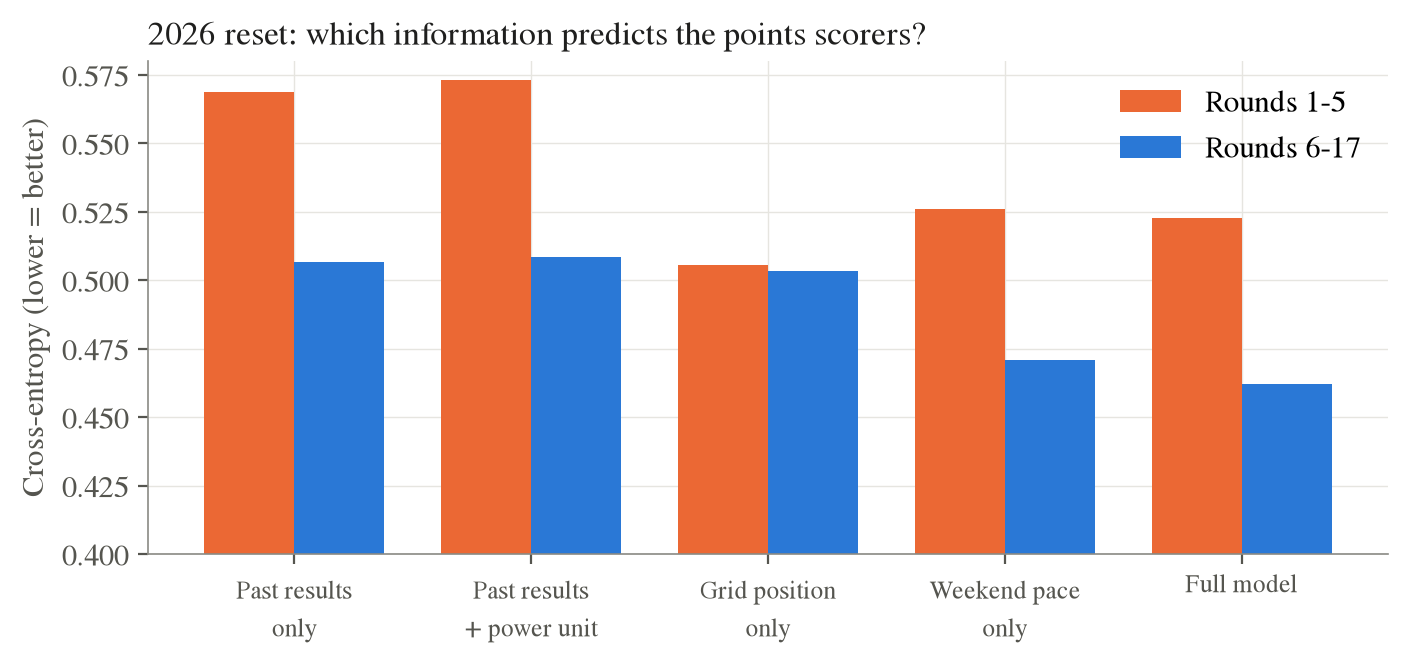

In [3]:
for test in ['Reset 2026', 'Reset 2014']:
    m = R[test]['models']
    e = m['Past results only']['logloss_early'] - m['Weekend pace only']['logloss_early']
    l = m['Past results only']['logloss_late'] - m['Weekend pace only']['logloss_late']
    pu = m['Full model']['logloss'] - m['Full model (no power unit)']['logloss']
    print(f"{test}: H1 weekend beats past early by {e:+.4f} cross-entropy; H2 gap later {l:+.4f} (positive = weekend better); power unit changes the full model by {pu:+.4f}")
from IPython.display import Image; display(Image('../figures/06_reset_2026.png', width=700))

**Reading.** H1 holds in both resets: in the first five races, the weekend's pace predicts the points scorers better than past results. H2 holds too: the gap shrinks as the season goes on (in 2014, past results even become the better source after round 5). The full model, which combines both, is best overall. The power-unit variables do **not** improve the full model: the engine's past results are themselves "past results", which a reset makes stale; what matters is visible on Saturday.